# Анализ туристских потоков России

В этом проекте я бы хотела проанализировать туристские потоки России в двух срезах данных:

1. **Динамика по годам (2014-2025):** как менялся въездной и выездной потоки, как на них повлияла пандемия COVID-19;
2. **Топ-10 стран (2025):** откуда больше всего приезжают в Россию и куда чаще всего уезжаю россияне.

***Цель работы*** - выявить основные тенденции в туристских потоках России и определить страны, которые играют ключевую роль во въездном и выездном туризме.

## Импортирование библиотек

In [152]:
# Создание папки для графиков и других иллюстраций, созданных в ходе обработки данных
import os
os.makedirs('plots', exist_ok=True)

# Библиотеки для построения графиков
import matplotlib.pyplot as plt

# Библиотека для работы с табличными данными
import numpy as np
import pandas as pd

## Данные

Данные о въездных и выездных туристских поездках за период с 2014 по 2025 гг. и оценка туристских потоков за 2022-2025 гг.

**Источник:** Росстат (URL: https://rosstat.gov.ru/statistics/turizm), раздел "Туризм", **обработка:** Я.

В датасете нас будут интересовать:

* год поездки;
* число въездных поездок (*измеряется в тыс.*);
* число выездных поездок (*измеряется в тыс.*);
* регион России или название страны;
* число туристских поездок в регион.


## Добавление данных

In [174]:
data_path_flow = ('data/modified_data/Poezdki/flow_all.csv')
flow_df = pd.read_csv(data_path_flow, sep=';')

data_path_inbound = ('data/modified_data/Poezdki/2025_country_flow_1.csv')
inbound_2025_df = pd.read_csv(data_path_inbound, sep=';')

data_path_outbound = ('data/modified_data/Poezdki/2025_russian_to_country_1.csv')
outbound_2025_df = pd.read_csv(data_path_outbound, sep=';')

data_path_tour_flow_regions = ('data/modified_data/Turpotok/2025_tour_flow_regions_1.csv')
tour_flow_regions_df = pd.read_csv(data_path_tour_flow_regions, sep=';')

print(flow_df.head())
print()
print(inbound_2025_df.head())
print()
print(outbound_2025_df.head())
print()
print(tour_flow_regions_df.head())

   year  inbound  outbound
0  2014    25438     42921
1  2015    26852     34390
2  2016    24571     31659
3  2017    24390     39629
4  2018    24551     41964

       Country  Mean
0      Абхазия   606
1    Австралия     2
2      Австрия     5
3  Азербайджан   200
4    Аргентина     3

       Country  Mean
0      Абхазия  5606
1      Австрия     0
2  Азербайджан   502
3      Армения   990
4      Бахрейн    22

                Regions       Mean
0  Белгородская область   964373.0
1      Брянская область   444311.0
2  Владимирская область  1130070.0
3   Воронежская область  1551512.0
4    Ивановская область   438458.0


## 1. Динамика въездного и выездного потока (2014-2025)

***Линейный график:*** отдельно въезд иностранцев в Россию и выезд россиян за рубеж. КРасным выделен период ковида (*2020-2021*).

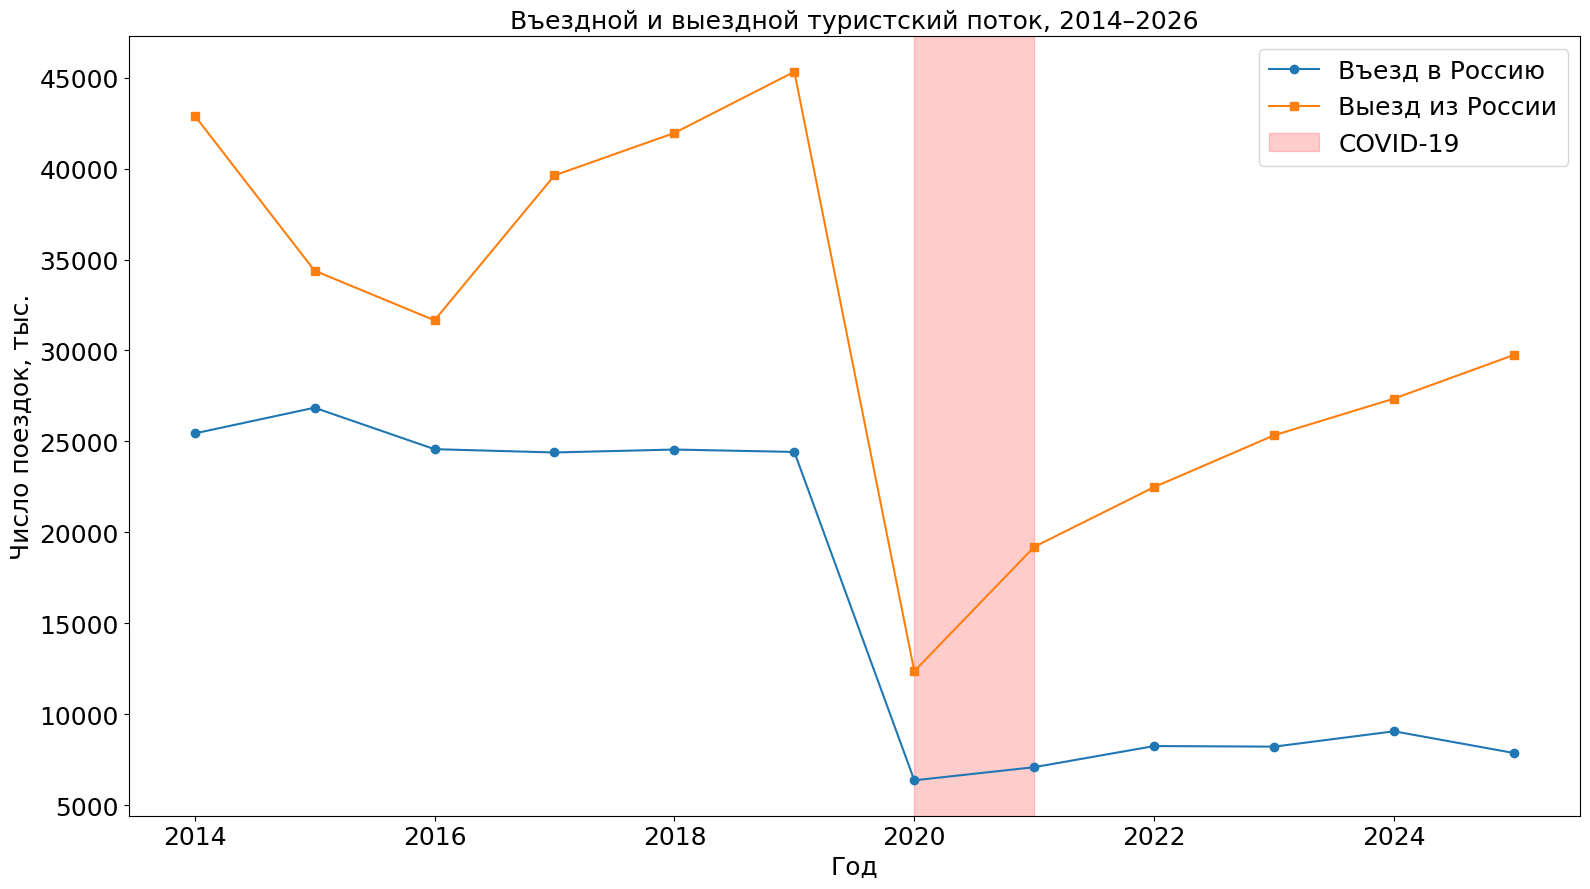

In [156]:
x = flow_df['year']
y1 = flow_df['inbound']
y2 = flow_df['outbound']

fig, ax = plt.subplots(figsize=(16,9))
ax.plot(x, y1, marker='o', label='Въезд в Россию') # marker='o' - добавляет кружки
ax.plot(x, y2, marker='s', label='Выезд из России') # marker='s' - добавляет квадратики
ax.axvspan(2020, 2021, alpha=0.2, color='red', label='COVID-19')
ax.set_xlabel('Год', fontsize=18)
ax.set_ylabel('Число поездок, тыс.', fontsize=18)
ax.set_title('Въездной и выездной туристский поток, 2014–2026', fontsize=18)
ax.legend(fontsize=18)
ax.tick_params(labelsize=18)

plt.tight_layout()

plt.savefig("plots/all_flow.png", dpi=300)

**Вывод:** оба туристских потока (*въездной и выездной*) до 2019 года росли (*не всегда стабильно, но всё же🙃*), и стоит отметить, что выездной поток всегда превышал въездной, что может быть связано с рядом факторов - от климатических до социально-инфраструктурных. В 2019-2020 гг. оба потока резко упали из-за пандемии COVID-19, но в 2021 году частично стали восстанавливаться, причем выездной поток восстанавливался гораздо быстрее въездного.

## 2. Соотношение въездного и выездного потока по годам

На предыдущем графике видно, *как* менялись потоки во времени. График №2 может показать ситуацию несколько с другой стороны: в таблице помимо столбца ***year***, есть еще два - ***inbound*** (въездные потоки) и ***outbound*** (выездные потоки), при сравнении значения которых можно увидеть разрыв между ними.

Этот график может ответить на такие вопросы, как:

* в какие годы выезд россиян особенно сильно превышал въезд иностранцев;
* как пандемия 2020-2021 гг. повлияла на каждый из потоков по отдельности;
* насколько быстро оба потока восстановились после COVID-19.

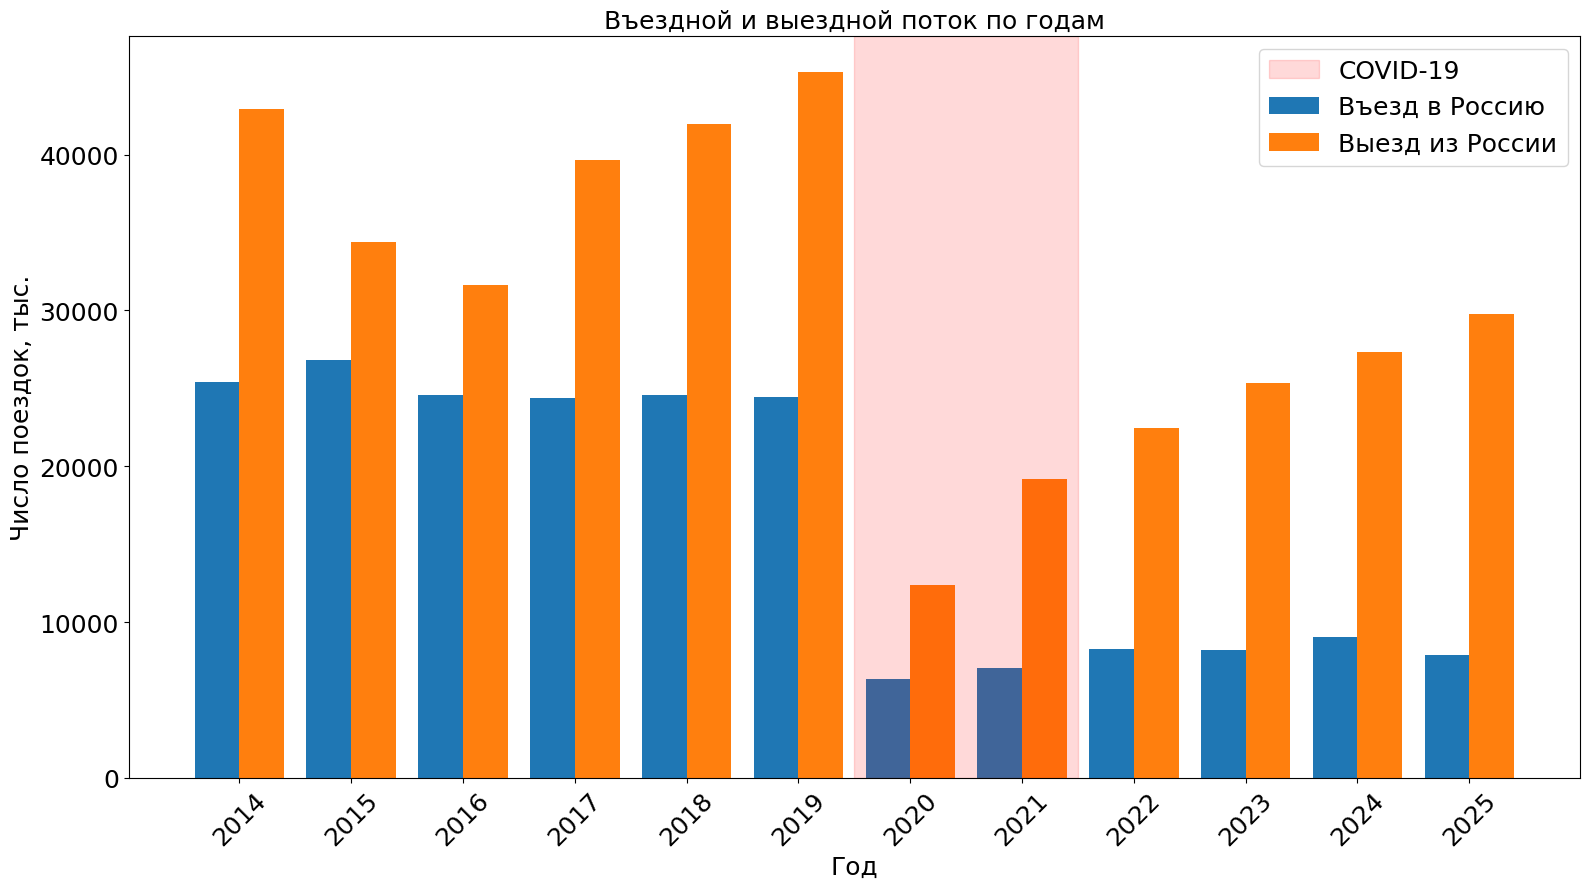

In [165]:
x = np.arange(len(flows_df))
x1 = flow_df['year']
y1 = flow_df['inbound']
y2 = flow_df['outbound']
width = 0.4

fig, ax = plt.subplots(figsize=(16,9))
ax.bar(x - width/2, y1, width, label='Въезд в Россию')
ax.bar(x + width/2, y2, width, label='Выезд из России')
ax.set_xticks(x)
ax.set_xticklabels(x1, rotation=45)
ax.axvspan(5.5, 7.5, alpha=0.15, color='red', label='COVID-19')
ax.set_xlabel('Год', fontsize=18)
ax.set_ylabel('Число поездок, тыс.', fontsize=18)
ax.set_title('Въездной и выездной поток по годам', fontsize=18)
ax.legend(fontsize=18)
ax.tick_params(labelsize=18)

plt.tight_layout()

plt.savefig("plots/all_flow_bars.png", dpi=300)

**Вывод:** в доковидные годы выезд россиян стабильно превышал въезд иностранных граждан - примерно в 2 раза (*среднее значение - 2,092*). В 2020 году оба потока резко обрушились: въезд упал до 6359, выезд - до 12361. После 2021 года выездной поток восстанавливался быстрее: к 2024 году он достиг 27355, тогда как въездной - 9054 только. Это может говорить о том, что зарубежные поездки россиян восстановились раньше, чем въездной туризм в Россию.

## 3. Топ-10 стран по въезду в Россию (2025)

***Горизонтальная столбчатая диаграмма:*** 10 стран-лидеров по числу въездных туристских поездок в Россию в 2025 году. Страны расположены по убыванию потока.

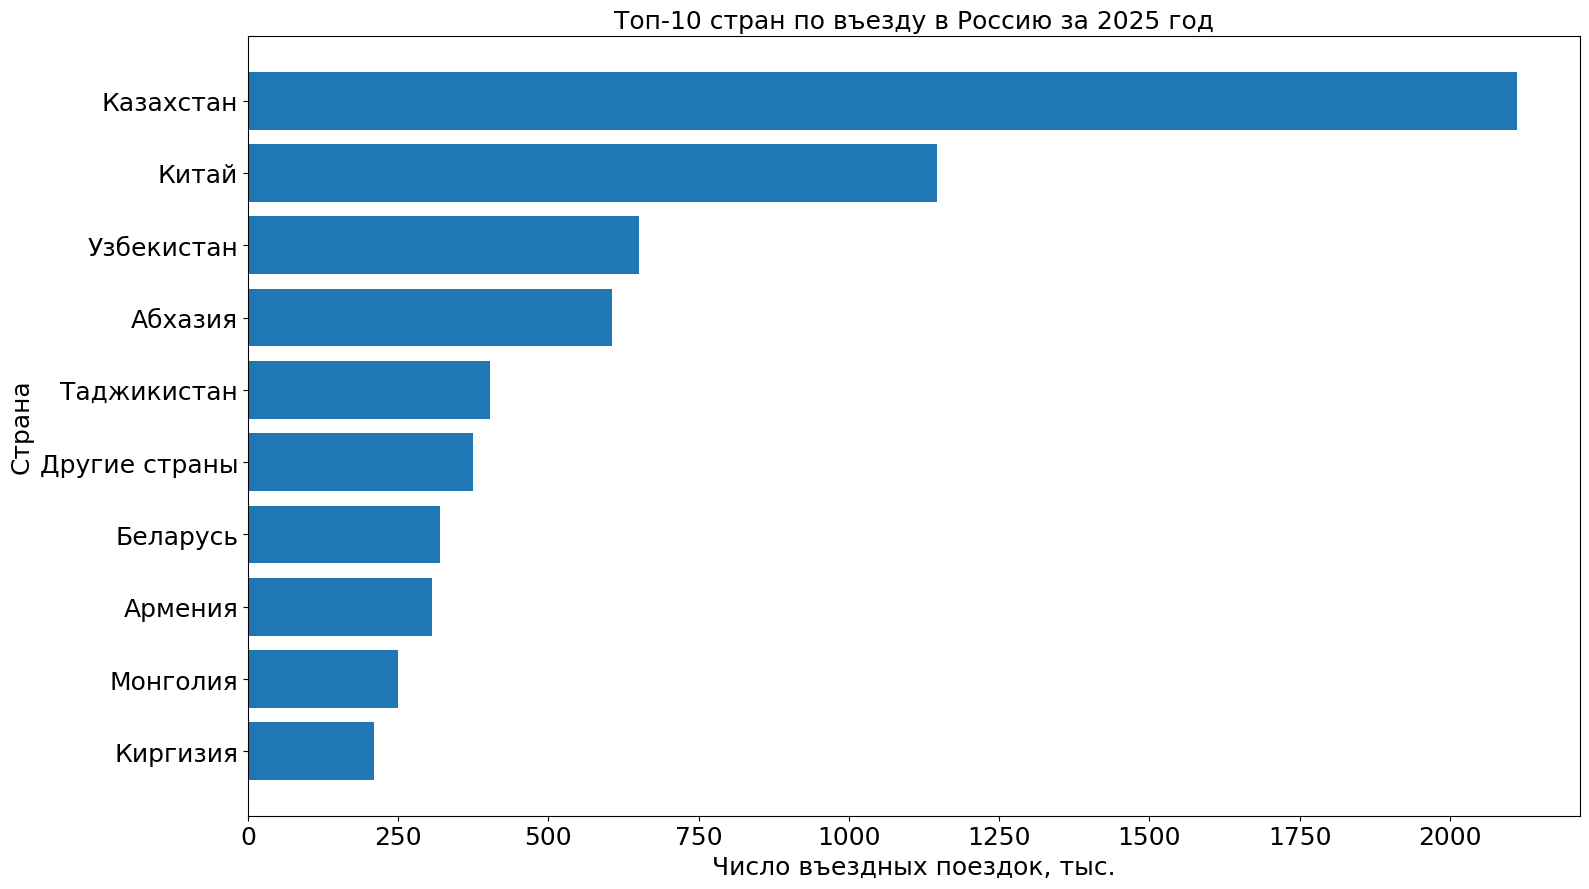

In [166]:
# Топ-10 и диаграмма
top_10_inbound_2025 = inbound_2025_df.nlargest(10, 'Mean').sort_values('Mean', ascending=True)

fig, ax = plt.subplots(figsize=(16, 9))
ax.barh(top_10_inbound_2025['Country'], top_10_inbound_2025['Mean'])
ax.set_xlabel('Число въездных поездок, тыс.', fontsize=18)
ax.set_ylabel('Страна', fontsize=18)
ax.set_title('Топ-10 стран по въезду в Россию за 2025 год', fontsize=18)
ax.tick_params(labelsize=18)

plt.tight_layout()

plt.savefig('plots/top_10_inbound_2025.png', dpi=300)

***Вывод:*** в 2025 году лидером по въезду в Россию стал Казахстан - это можно объяснить близостью стран, безвизовым режимом и общим рынком труда. Далее лидируют Китай и Узбекистан. Преимущественно в том-10 вошли страны СНГ, а также некоторые азиатские страны, что отражает структуру въездного потока: значительная частьпоездок скорее всего связана с трудовой миграцией, учебой и частными визитами, а не только с туризмом.

## 4. Топ-10 стран по выезду россиян за рубеж (2025)

***Горизонтальная столбчатая диаграмма:*** страны-лидеры по числу выездных поездок россиян за рубеж в 2025 году.

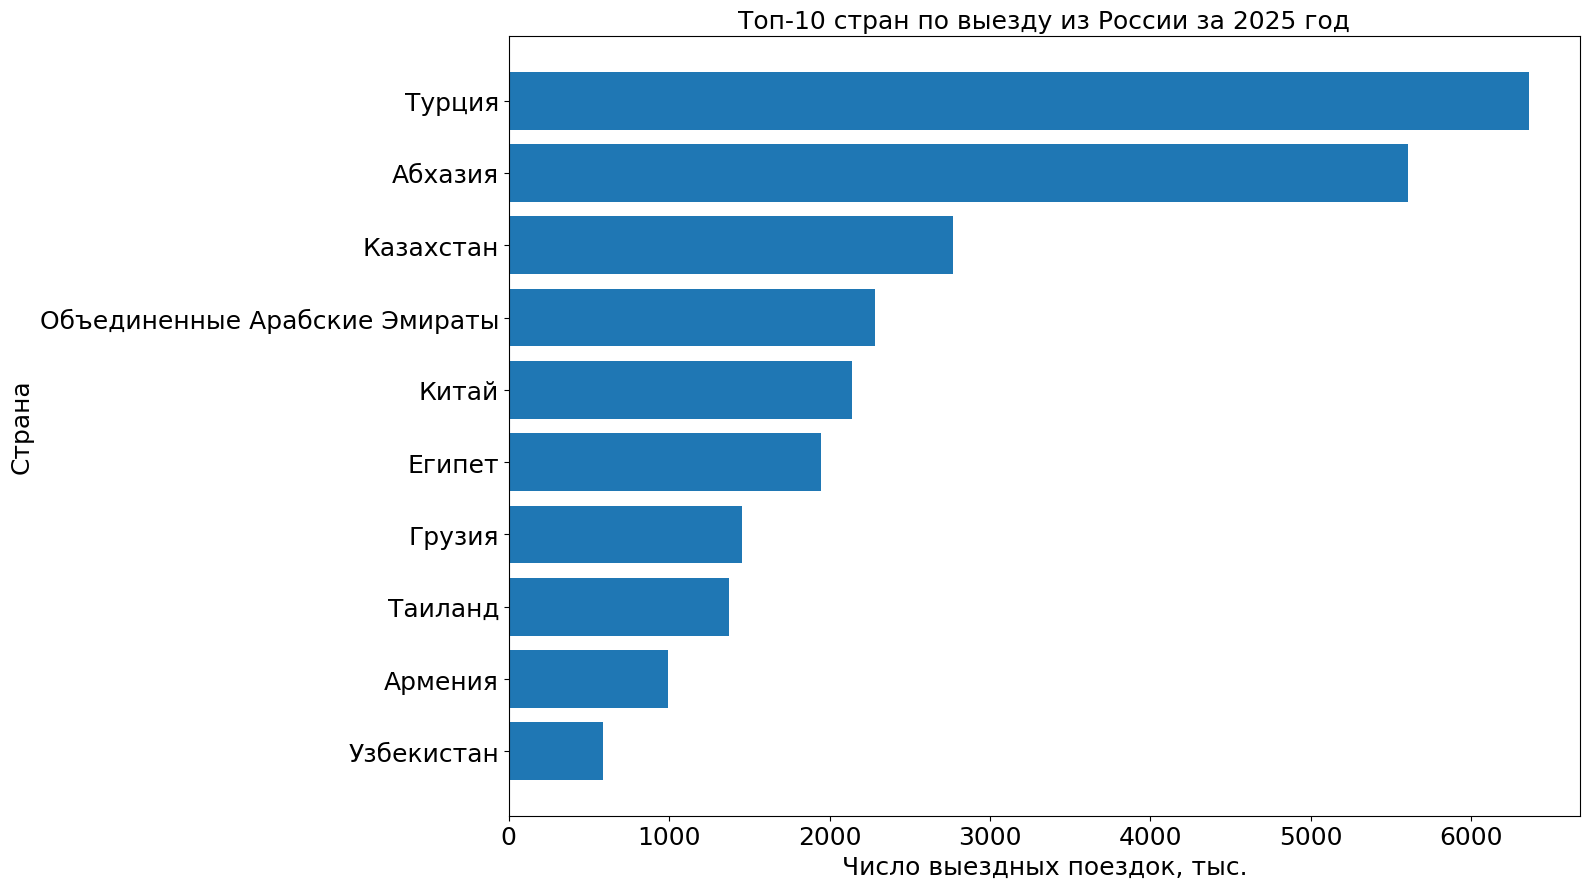

In [169]:
top_10_outbound_2025 = outbound_2025_df.nlargest(10, 'Mean').sort_values('Mean', ascending=True)

fig, ax = plt.subplots(figsize=(16,9))
ax.barh(top_10_outbound_2025['Country'], top_10_outbound_2025['Mean'])
ax.set_xlabel('Число выездных поездок, тыс.', fontsize=18)
ax.set_ylabel('Страна', fontsize=18)
ax.set_title('Топ-10 стран по выезду из России за 2025 год', fontsize=18)
ax.tick_params(labelsize=18)

plt.tight_layout()

plt.savefig('plots/top_10_outbound_2025.png', dpi=300)

**Вывод:** в 2025 году россияне чаще всего уезжали в Турцию - она занимает первое место. Далее идут Абхазия, Казахстан и ОАЭ. В топ-10 как привычные курортные направления (*Турция, ОАЭ, Египет, Таиланд*), так и страны СНГ (*Казахстан, Армения, Узбекистан*), что отражает разные цели поездок - от отдыха до деловых и частных визитов. В отличие от въездного потока, где лидировали страны СНГ и Китай, в выездном преобладают туристические направления.

## 5. Топ-10 регионов России по туристскому потоку (2025)

***Горизонтальная столбчатая диаграмма:*** регионы-лидеры по числу туристических поездок (российские и инотранные туристы) в 2025 году.

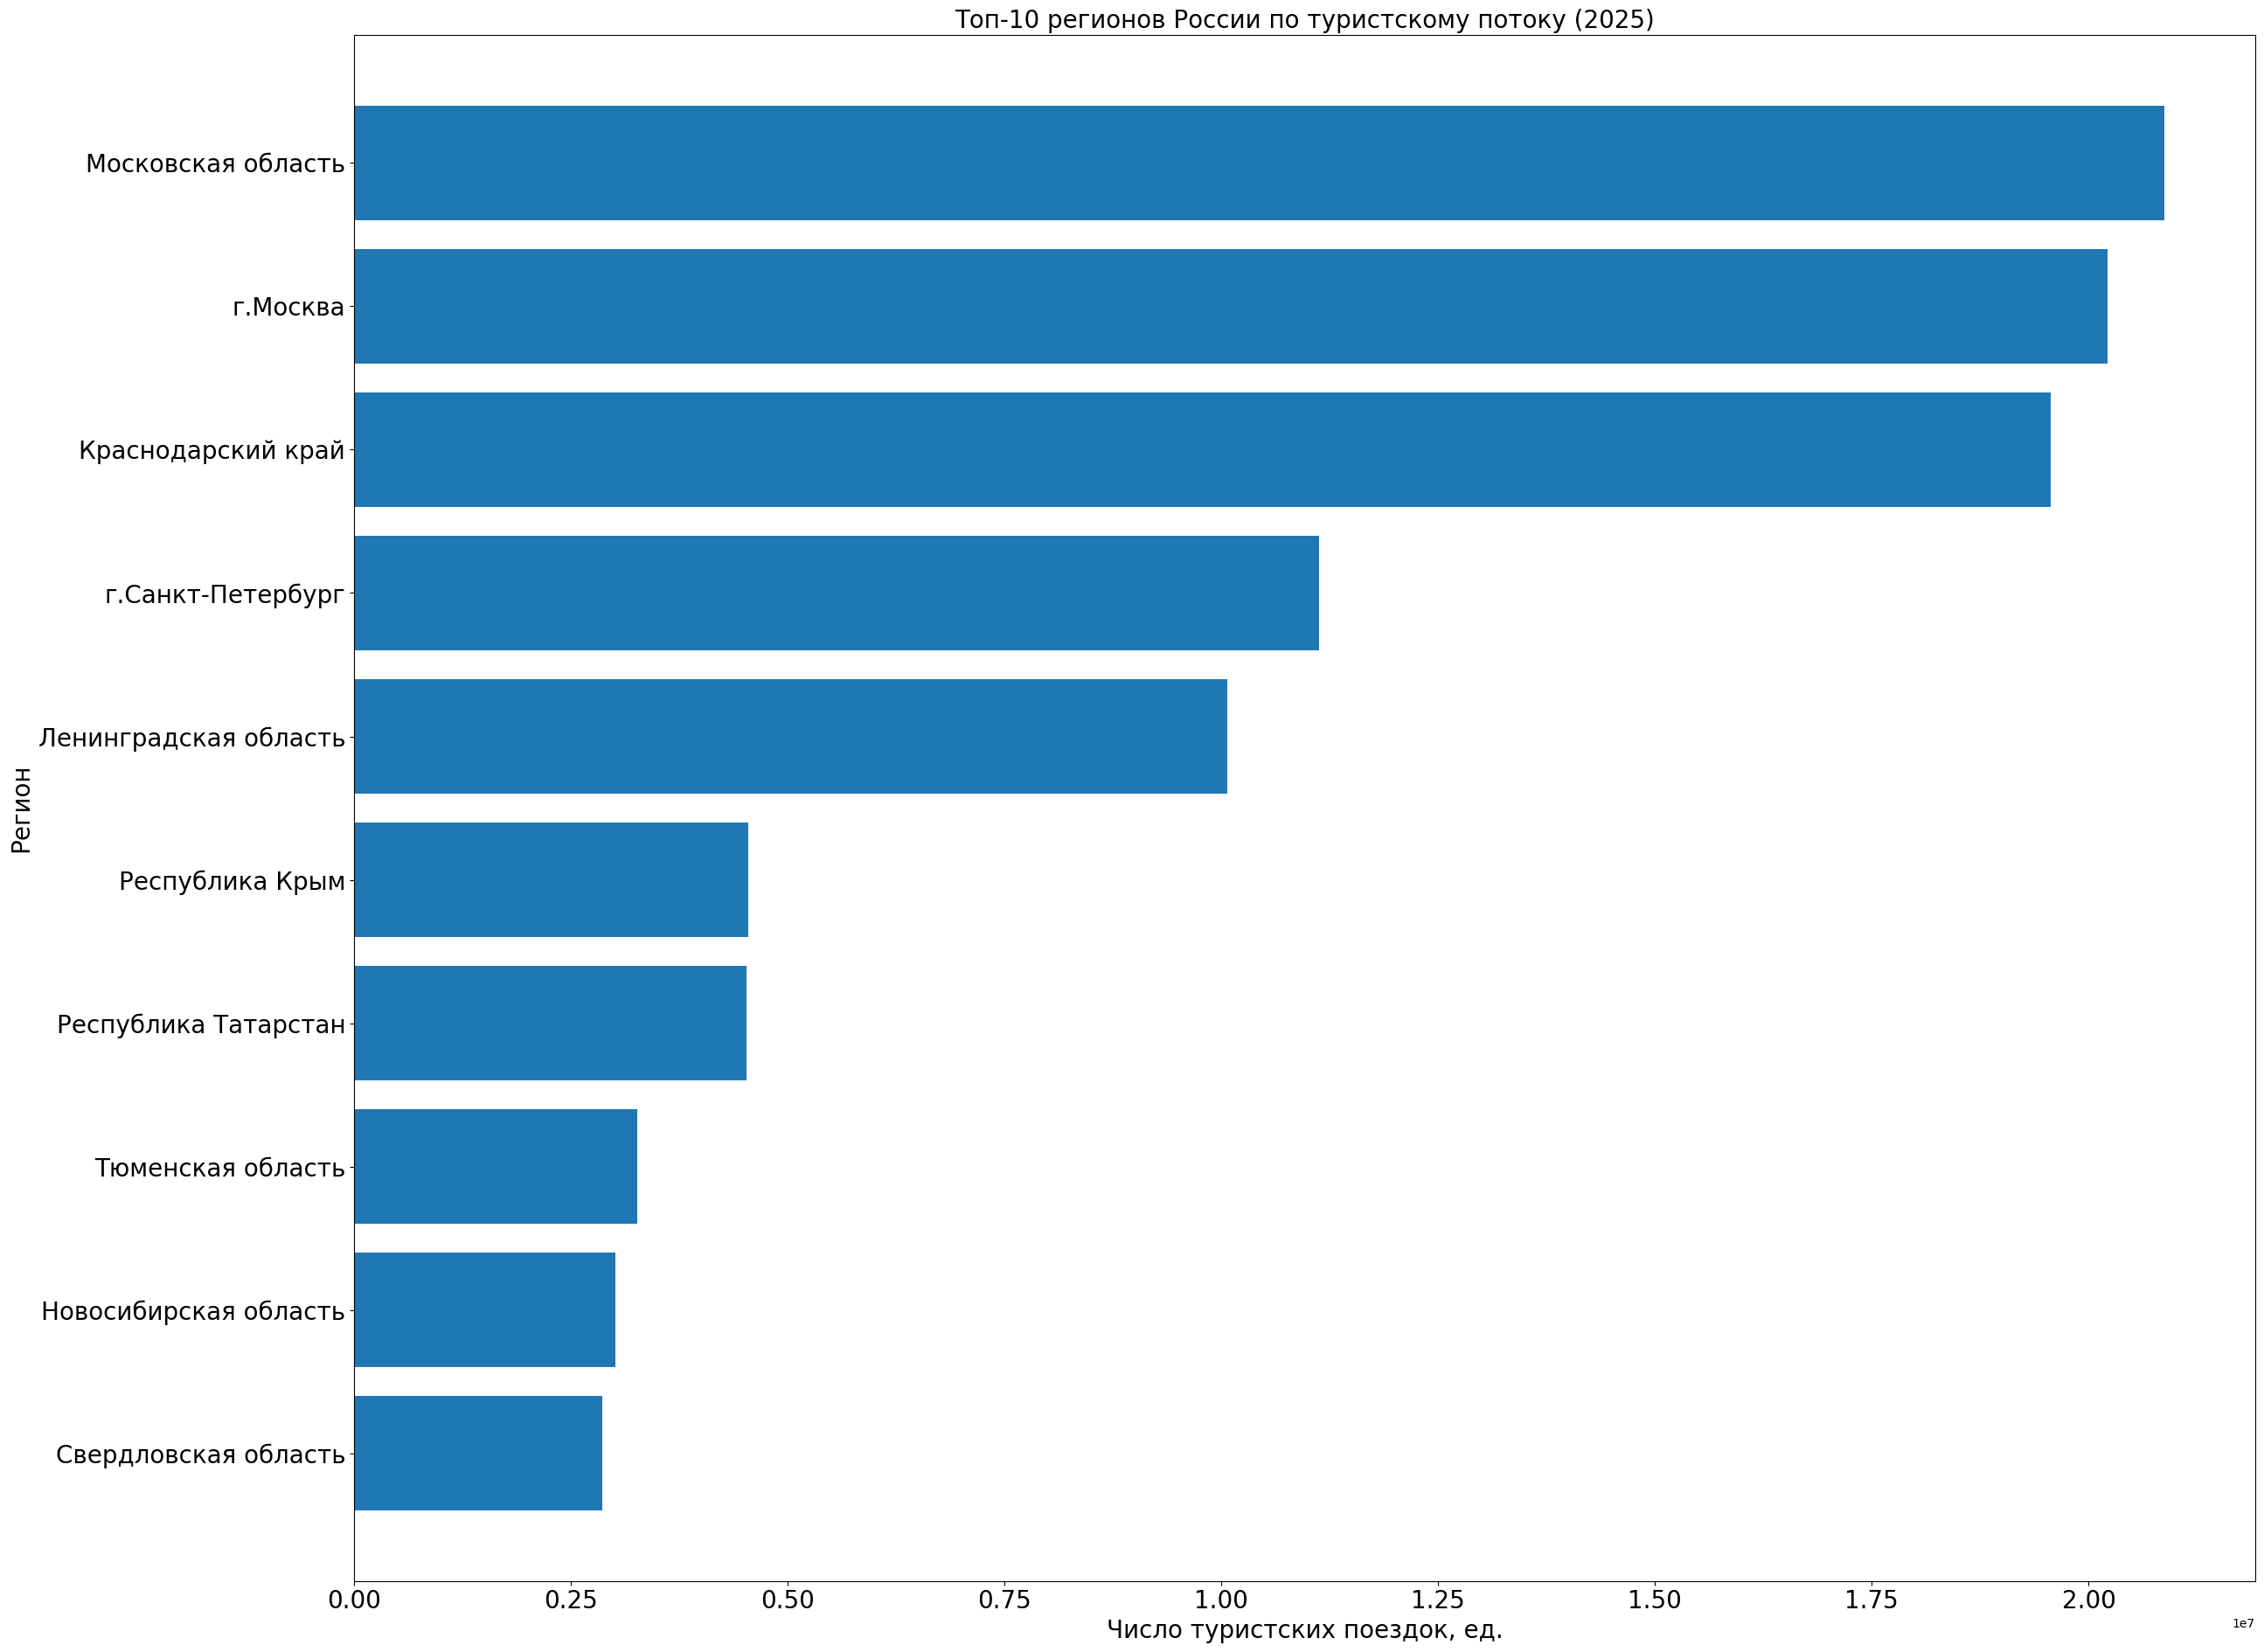

In [177]:
# Топ-10
top_10_regions = tour_flow_regions_df.nlargest(10, 'Mean').sort_values('Mean', ascending=True)

fig, ax = plt.subplots(figsize=(26,19))
ax.barh(top_10_regions['Regions'], top_10_regions['Mean'])
ax.set_xlabel('Число туристских поездок, ед.', fontsize=20)
ax.set_ylabel('Регион', fontsize=20)
ax.set_title('Топ-10 регионов России по туристскому потоку (2025)', fontsize=20)
ax.tick_params(labelsize=20)

plt.tight_layout()

plt.savefig("plots/top_10_regions_2025.png", dpi=300)

**Вывод:** лидерами по туристскому потоку в 2025 году стали Московская область и Москва - вместе они образуют крупнейшую агломерацию страны, привлекающую туристов со всей России и не только. Далее идут Краснодарский край Санкт-Петербург с Ленинградской областью - главные курортные и культурные центры. В топ-10 также вошли Республика Крым (*курортное направление*) и крупные промышленные центры (*Республика Татарстан, Тюменская, Новосибирская и Свердловская области*), что отражает деловую и событийную составляющую туристского потока.

## ✨Общий вывод✨

Анализ показал, что туристские потоки России имеют разную структуру в зависимости от того, что мы анализируем:

1. **По годам:** выезд россиян стабильно превышал въезд иностранцев; пандемия 2020-2021 гг. обрушила оба потока, но выездной восстановился быстрее.
2. **По странам въезда:** лидируют страны СНГ и Китай (*Казахстан, Китай, Узбекистан*), что связано с трудовой миграцией, учёбой и частными визитами.
3. **По странам выезда:** преобладают курортные направления (*Турция, ОАЭ, Египет, Таиланд*) и страны СНГ (*Узбекистан Казахстан, Армения*).
4. **По регионам:** лидируют Московская агломерация, курортные регионы (*Краснодарский край, Крым*) и крупные промышленные центры.

Таким образом, въездной туризм в Россию в значительной степени связан с деловыми и трудовыми поездками, тогда как выездной — с отдыхом. Внутри страны турпоток концентрируется вокруг крупнейших агломераций и курортов.